# Train an HGT-v2 + TCN relative-motion forecaster

Run **33_prepare_relative_motion_forecasting.ipynb** first. This notebook trains one graph neural network to forecast the opposing aircraft's North/West/Up position and velocity relative to the observer at **+1, +2 and +5 seconds**. It uses notebook 33's exact 91-feature, 20-frame policy histories and masked six-vector targets.

The architecture is the regression counterpart of notebook 28. Every frame becomes a heterogeneous graph with two aircraft, four friendly missiles and four hostile missiles. Two HGT-v2 layers use typed ownership/targeting relations, relation-family gates, 18 physical edge features and the learned closest-approach threat prior. Missile slots remain frame-local sets rather than persistent tracks. The graph readout enters notebook 28's four residual causal TCN blocks with width 96, kernel size 3 and dilations 1/2/4/8. Their 61-frame receptive field covers the complete 20-frame history.

The output head regresses three six-vectors. Training predicts residuals from the constant-relative-velocity baseline, divided by notebook 33's training-only per-horizon scales. A masked Smooth-L1 objective gives every available horizon equal sample weight; unavailable post-termination horizons contribute nothing. Reports restore physical units and compare 3D position and velocity-vector errors with the saved constant-relative-velocity baseline.

Checkpoint selection uses the mean test normalized RMSE across the three horizons. The partition named `test` is therefore a model-selection set, matching notebook 28's convention. Validation remains untouched until training and checkpoint selection finish. One seed is a single fit, not a variance estimate.

In [1]:
from pathlib import Path
import os
import sys

root_override = os.environ.get("BVR_RELATIVE_MOTION_ROOT")
candidates = ([Path(root_override).expanduser()] if root_override else
              [Path.cwd(), *Path.cwd().parents])
ROOT = next((path.resolve() for path in candidates
             if (path / "bvr_behavior_prediction/forecasting/relative_motion_gnn.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Set BVR_RELATIVE_MOTION_ROOT to the Trajectory_Classification checkout.")
sys.path.insert(0, str(ROOT))

from bvr_behavior_prediction.notebook_runtime import require_pyarrow
require_pyarrow()
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from bvr_behavior_prediction.forecasting.relative_motion import (
    HORIZONS, RelativeMotionData, read_json, sha256, write_json,
)
from bvr_behavior_prediction.forecasting.relative_motion_gnn import (
    ARCHITECTURE, RelativeMotionHGTTCN, default_training_config, effective_precision,
    final_evaluation, train_model,
)

DATA_ROOT = ROOT / "artifacts/relative_motion_forecasting"
EXPERIMENT_ROOT = ROOT / "artifacts/relative_motion_gnn_forecasting"
EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
data_override = os.environ.get("BVR_RELATIVE_MOTION_DATA")
receipt_path = DATA_ROOT / "latest_dataset.json"
if not data_override and not receipt_path.exists():
    raise FileNotFoundError("Run notebook 33 first or set BVR_RELATIVE_MOTION_DATA.")
receipt = None if data_override else read_json(receipt_path)
DATA = Path(data_override or receipt["directory"]).expanduser().resolve()
if receipt and sha256(DATA / "manifest.json") != receipt["manifest_sha256"]:
    raise ValueError("Prepared data changed after notebook 33 completed.")
data = RelativeMotionData(DATA)

DEVICE = os.environ.get("BVR_RELATIVE_MOTION_DEVICE",
                        "cuda" if torch.cuda.is_available() else "cpu")
CONFIG = default_training_config()
CONFIG.update({
    "epochs": int(os.environ.get("BVR_RELATIVE_MOTION_EPOCHS", CONFIG["epochs"])),
    "batch_size": int(os.environ.get("BVR_RELATIVE_MOTION_BATCH_SIZE", CONFIG["batch_size"])),
    "evaluation_batch_size": int(os.environ.get("BVR_RELATIVE_MOTION_EVAL_BATCH_SIZE",
                                                    CONFIG["evaluation_batch_size"])),
    "cpu_threads": int(os.environ.get("BVR_RELATIVE_MOTION_CPU_THREADS",
                                         CONFIG["cpu_threads"])),
})
TRAIN_MODEL = True
RESUME = False
REEVALUATE_SAVED = False
EXISTING_RUN = None  # Required for resume or report-only execution.
if (RESUME or not TRAIN_MODEL) and not EXISTING_RUN:
    raise ValueError("Set EXISTING_RUN when resuming or reporting.")
if EXISTING_RUN and TRAIN_MODEL and not RESUME:
    raise ValueError("Use RESUME=True or clear EXISTING_RUN for a fresh fit.")
stamp = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
RUN = (Path(EXISTING_RUN).expanduser().resolve() if EXISTING_RUN else
       EXPERIMENT_ROOT / "runs" / f"relative-motion-hgt-tcn-s{CONFIG['seed']}_{stamp}")
receptive_field = 1 + 2 * (CONFIG["tcn_kernel_size"] - 1) * sum(CONFIG["tcn_dilations"])
preview = RelativeMotionHGTTCN(**{key: CONFIG[key] for key in (
    "width", "graph_width", "graph_layers", "graph_heads", "tcn_kernel_size",
    "tcn_dilations", "dropout", "threat_cpa_horizon_s", "threat_time_scale_s",
    "threat_prior_strength", "missile_distance_floor_m", "missile_distance_power")},
    mean=data.mean, std=data.std)
display(pd.Series({"architecture": ARCHITECTURE, "device": DEVICE,
                   "effective_precision": effective_precision(torch.device(DEVICE), CONFIG["precision"]),
                   "parameters": sum(parameter.numel() for parameter in preview.parameters()),
                   "input_features": 91, "history_steps": data.manifest["history_steps"],
                   "tcn_receptive_field": receptive_field, "run": str(RUN)}))
display(pd.Series(CONFIG))
display(pd.DataFrame(data.manifest["counts"]).T)
del preview
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(torch.device(DEVICE)))

architecture                                  hgt_v2_tcn_relative_motion
device                                                              cuda
effective_precision                                                 bf16
parameters                                                        467354
input_features                                                        91
history_steps                                                         20
tcn_receptive_field                                                   61
run                    C:\Users\theon\Trajectory_Classification\artif...
dtype: object

architecture                 hgt_v2_tcn_relative_motion
seed                                                 42
width                                                96
graph_width                                          64
graph_layers                                          2
graph_heads                                           4
tcn_kernel_size                                       3
tcn_dilations                              [1, 2, 4, 8]
dropout                                            0.25
threat_cpa_horizon_s                               30.0
threat_time_scale_s                                 5.0
threat_prior_strength                               1.0
missile_distance_floor_m                         1000.0
missile_distance_power                              1.0
epochs                                              100
batch_size                                         1024
evaluation_batch_size                              1024
learning_rate                                   

,groups,perspective_episodes,physical_flights,windows,valid_by_horizon
train,4000,8000,4000,396556,"[396556, 395692, 388556]"
test,3000,6000,3000,1167032,"[1167032, 1161032, 1143032]"
validation,3000,6000,3000,1200344,"[1200344, 1194344, 1176344]"


GPU: NVIDIA GeForce RTX 5080 Laptop GPU


## Fit one graph/temporal model

Each epoch trains on only notebook 33's retained, non-overlapping training histories. AdamW, gradient clipping, a five-percent warm-up followed by cosine decay, matrix/tensor L1 regularization and BF16-on-supported-CUDA follow notebook 28's training style. HGT attention reductions and physical graph calculations remain FP32. CPU execution falls back to FP32.

The saved run pins the prepared-data manifest, feature order, target contract, complete configuration, model source, reused HGT source, dependency versions and effective precision. `last.pt` is a complete restart checkpoint; `best.pt` is the test-selected model. A resume refuses changed data, code or settings. Start a fresh run when changing the graph, TCN, loss, target scales, batch size or epoch budget.

In [2]:
def epoch_output(row, metrics):
    test = metrics.loc[metrics.split.eq("test"), [
        "horizon_s", "position_mae_m", "velocity_mae_mps",
        "baseline_position_mae_m", "baseline_velocity_mae_mps",
    ]]
    print(f"Epoch {row['epoch']}: test normalized RMSE={row['test_normalized_rmse']:.5f}, "
          f"train/test Huber={row['train_huber']:.5f}/{row['test_huber']:.5f}, "
          f"LR={row['learning_rate']:.3g}, best={row['best_epoch']}, "
          f"stale={row['stale_epochs']}, {row['seconds']:.1f}s", flush=True)
    display(test.round(3))

if TRAIN_MODEL:
    history = train_model(data, RUN, CONFIG, device=DEVICE, resume=RESUME,
                          callback=epoch_output)
else:
    history = pd.read_csv(RUN / "history.csv")
status = read_json(RUN / "training_status.json")
if status["status"] not in {"completed", "early_stopped"}:
    raise ValueError("Training has not concluded.")
saved_run = read_json(RUN / "run.json")
if saved_run["data_manifest_sha256"] != sha256(DATA / "manifest.json"):
    raise ValueError("Saved run belongs to another prepared dataset.")
if saved_run["feature_names"] != data.manifest["features"]:
    raise ValueError("Saved feature order differs from notebook 33.")
display(history.tail())
print(status)

Epoch 1: test normalized RMSE=0.99279, train/test Huber=0.40281/0.41013, LR=8.4e-05, best=1, stale=0, 170.4s


,horizon_s,position_mae_m,velocity_mae_mps,baseline_position_mae_m,baseline_velocity_mae_mps
3,1.0,16.059,31.388,16.250,31.748
4,2.0,62.445,61.364,63.256,62.070
5,5.0,363.324,139.788,369.919,143.461


Epoch 2: test normalized RMSE=0.80841, train/test Huber=0.28450/0.28897, LR=0.000138, best=2, stale=0, 145.2s


,horizon_s,position_mae_m,velocity_mae_mps,baseline_position_mae_m,baseline_velocity_mae_mps
3,1.0,12.868,25.284,16.250,31.748
4,2.0,50.173,49.351,63.256,62.070
5,5.0,290.333,113.065,369.919,143.461


Epoch 3: test normalized RMSE=0.64151, train/test Huber=0.18856/0.19085, LR=0.000192, best=3, stale=0, 150.2s


,horizon_s,position_mae_m,velocity_mae_mps,baseline_position_mae_m,baseline_velocity_mae_mps
3,1.0,9.966,19.641,16.250,31.748
4,2.0,38.992,38.842,63.256,62.070
5,5.0,229.754,91.671,369.919,143.461


... (192 outputs left out)

Epoch 100: test normalized RMSE=0.32932, train/test Huber=0.05390/0.05459, LR=1.5e-05, best=100, stale=0, 144.2s


,horizon_s,position_mae_m,velocity_mae_mps,baseline_position_mae_m,baseline_velocity_mae_mps
3,1.0,3.296,7.491,16.250,31.748
4,2.0,15.817,18.917,63.256,62.070
5,5.0,126.632,60.117,369.919,143.461


,epoch,train_huber,test_huber,test_normalized_rmse,train_batch_huber,learning_rate,improved,best_epoch,best_test_normalized_rmse,stale_epochs,early_stopped,seconds
95,96,0.054156,0.054852,0.330123,0.068240,0.000016,True,96,0.330123,0,False,147.542395
96,97,0.054000,0.054693,0.329642,0.068076,0.000016,True,97,0.329642,0,False,150.316369
97,98,0.053935,0.054643,0.329539,0.068037,0.000015,True,98,0.329539,0,False,145.642979
98,99,0.053941,0.054620,0.329448,0.067992,0.000015,True,99,0.329448,0,False,145.118593
99,100,0.053901,0.054586,0.329320,0.068030,0.000015,True,100,0.329320,0,False,144.197302


{'status': 'completed', 'epoch': 100, 'best_epoch': 100, 'best_test_normalized_rmse': 0.3293196130181}


## Final physical-unit evaluation

Only this cell evaluates validation. The selected checkpoint is decoded as `constant-relative-velocity baseline + predicted residual`. Position error is the 3D distance between predicted and true relative positions; velocity error is the Euclidean difference between the predicted and true relative velocity vectors. Component RMSE values retain signed-axis information. The constant-relative-velocity columns are the no-learning reference on the identical masked examples.

Prediction files contain sample IDs, masks, model predictions, physical targets and baselines for reproducible downstream diagnostics. They can be large for the full notebook-32 corpus. Set `REEVALUATE_SAVED=True` only when deliberately replacing an existing final evaluation.

,split,horizon_s,samples,normalized_rmse,position_mae_m,baseline_position_mae_m,position_mae_improvement_pct,velocity_mae_mps,baseline_velocity_mae_mps,velocity_mae_improvement_pct
0,train,1.0,396556,0.254,3.274,16.039,79.585,7.450,31.338,76.227
1,train,2.0,395692,0.313,15.728,62.432,74.808,18.834,61.273,69.263
2,train,5.0,388556,0.414,125.897,365.023,65.510,59.737,141.572,57.805
3,test,1.0,1167032,0.256,3.296,16.250,79.717,7.491,31.748,76.405
4,test,2.0,1161032,0.315,15.817,63.256,74.996,18.917,62.070,69.522
5,test,5.0,1143032,0.417,126.632,369.919,65.768,60.117,143.461,58.095
6,validation,1.0,1200344,0.255,3.284,16.233,79.771,7.461,31.714,76.475
7,validation,2.0,1194344,0.314,15.750,63.187,75.074,18.839,62.002,69.616
8,validation,5.0,1176344,0.415,126.027,369.511,65.894,59.843,143.315,58.244


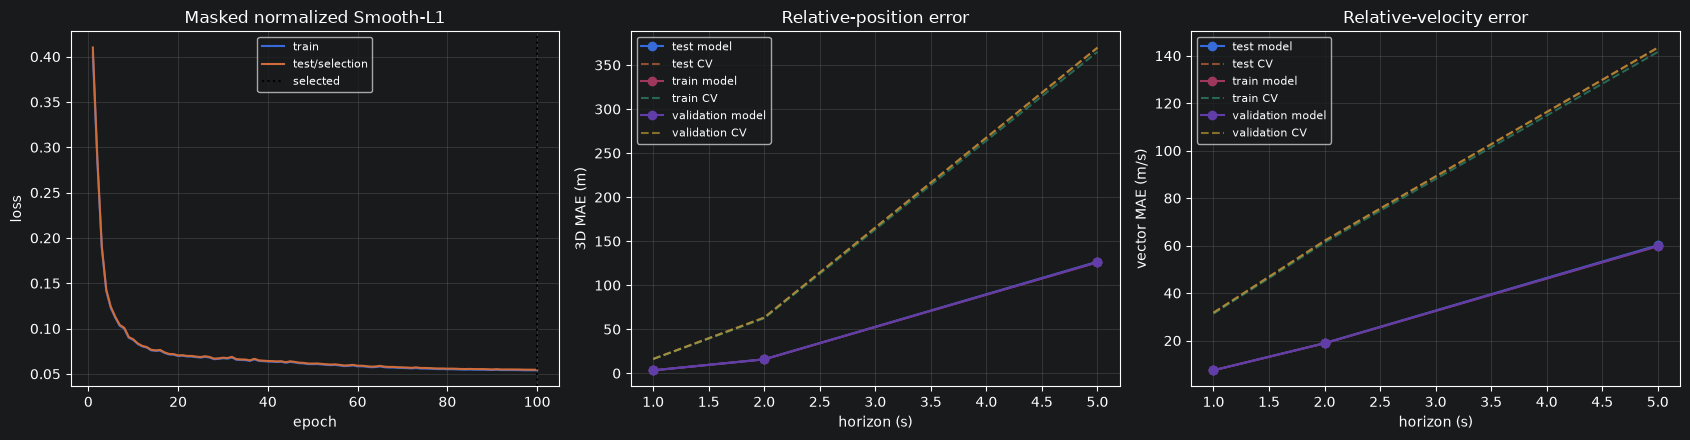

Completed HGT-v2 + TCN relative-motion run: C:\Users\theon\Trajectory_Classification\artifacts\relative_motion_gnn_forecasting\runs\relative-motion-hgt-tcn-s42_20261121T134258420447Z


In [3]:
metrics = final_evaluation(data, RUN, device=DEVICE,
                           batch_size=CONFIG["evaluation_batch_size"],
                           overwrite=REEVALUATE_SAVED)
position_ratio = metrics.position_mae_m.divide(metrics.baseline_position_mae_m)
velocity_ratio = metrics.velocity_mae_mps.divide(metrics.baseline_velocity_mae_mps)
metrics["position_mae_improvement_pct"] = (
    100 * (1 - position_ratio)).where(metrics.baseline_position_mae_m > 0)
metrics["velocity_mae_improvement_pct"] = (
    100 * (1 - velocity_ratio)).where(metrics.baseline_velocity_mae_mps > 0)
display(metrics[["split", "horizon_s", "samples", "normalized_rmse",
                 "position_mae_m", "baseline_position_mae_m",
                 "position_mae_improvement_pct", "velocity_mae_mps",
                 "baseline_velocity_mae_mps",
                 "velocity_mae_improvement_pct"]].round(3))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(history.epoch, history.train_huber, label="train")
axes[0].plot(history.epoch, history.test_huber, label="test/selection")
axes[0].axvline(read_json(RUN / "selection.json")["best_epoch"],
                color="black", linestyle=":", label="selected")
axes[0].set(title="Masked normalized Smooth-L1", xlabel="epoch", ylabel="loss")
for split, frame in metrics.groupby("split"):
    axes[1].plot(frame.horizon_s, frame.position_mae_m, marker="o", label=f"{split} model")
    axes[1].plot(frame.horizon_s, frame.baseline_position_mae_m, linestyle="--", alpha=.65,
                 label=f"{split} CV")
    axes[2].plot(frame.horizon_s, frame.velocity_mae_mps, marker="o", label=f"{split} model")
    axes[2].plot(frame.horizon_s, frame.baseline_velocity_mae_mps, linestyle="--", alpha=.65,
                 label=f"{split} CV")
axes[1].set(title="Relative-position error", xlabel="horizon (s)", ylabel="3D MAE (m)")
axes[2].set(title="Relative-velocity error", xlabel="horizon (s)", ylabel="vector MAE (m/s)")
for axis in axes:
    axis.grid(alpha=.25)
    axis.legend(fontsize=8)
fig.tight_layout()
figure_path = RUN / "final_relative_motion_metrics.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

write_json(EXPERIMENT_ROOT / "latest_run.json", {
    "directory": str(RUN), "data": str(DATA),
    "data_manifest_sha256": sha256(DATA / "manifest.json"),
    "run_manifest_sha256": sha256(RUN / "run.json"),
    "selection": read_json(RUN / "selection.json"),
})
print("Completed HGT-v2 + TCN relative-motion run:", RUN)